        # Lesson 7.4 · Smoothing Models
        ### Moving average, Simple Exponential Smoothing, Holt's trend, Holt-Winters seasonal

        | | |
        |---|---|
        | ⏱️ **Time** | about 90 minutes |
        | 📚 **Before you start** | Lessons 7.1 – 7.3 |
        | 🧪 **Format** | lesson → worked examples → exercises with hints → recap |

        ## 🎯 What you will be able to do after this notebook
        - Build a **moving-average** forecaster and explain the lag-vs-noise trade-off
- Derive and hand-code **Simple Exponential Smoothing (SES)** and interpret α
- Extend to **Holt's linear trend** (and its damped version) and **Holt-Winters seasonality**
- Compare all of them fairly with **walk-forward validation**

> 🌾 **The story so far.** The cooperative's manager has a spreadsheet and ten minutes. *"Give me a forecast I can compute by hand."* Smoothing models are exactly that: tiny formulas, surprisingly hard to beat.

In [1]:
import sys, pathlib, warnings
# Find the course folder (works no matter where Jupyter was started)
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "src" / "agrilab.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import agrilab as ag          # our helper library: src/agrilab.py

from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing
warnings.filterwarnings("ignore")   # (after imports: statsmodels re-enables its own warnings when imported)
ag.setup_plots()
ag.set_seed(42)
print("Setup complete. Course folder:", ROOT.name)

Setup complete. Course folder: course


## 1 · Averages as forecasts

The oldest forecasting idea: *the future will look like a typical recent past.*
We'll use **monthly** Central tomato prices (120 observations): small enough to refit hundreds of times, and a natural unit for a cooperative.

120 months | 2015-01-31 → 2024-12-31


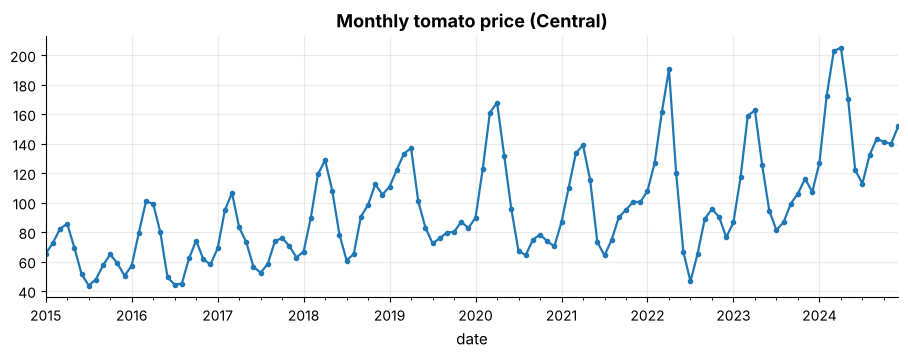

In [2]:
m = ag.price_series("tomato", "Central", "ME")
print(len(m), "months |", m.index[0].date(), "→", m.index[-1].date())
m.plot(figsize=(11, 3.4), marker="o", ms=3, title="Monthly tomato price (Central)"); plt.show()

### Moving average (MA) of order *k*
$$\hat y_{t+1} = \frac{1}{k}\,(y_t + y_{t-1} + \dots + y_{t-k+1})$$

Two jobs, easily confused:
- **Smoothing** (descriptive): average around a point to reveal the trend: a *centered* window.
- **Forecasting**: average the **last *k*** points and project it forward: a *trailing* window.

A short window reacts quickly but passes noise along. A long window is calm but **lags** reality. That's the whole trade-off:

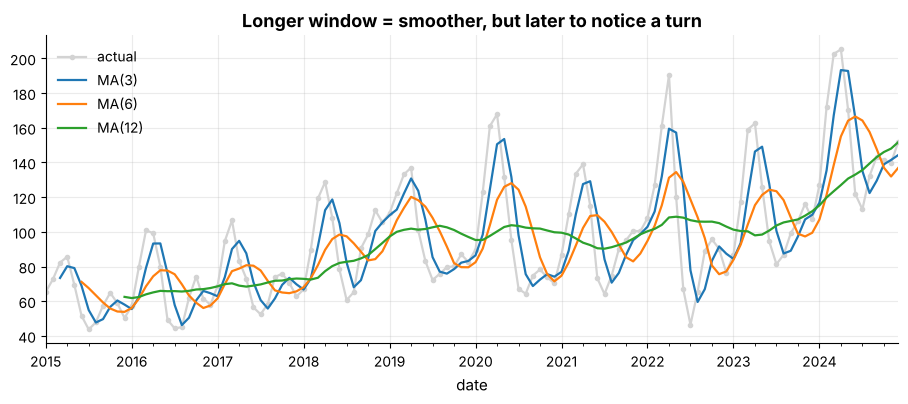

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
m.plot(ax=ax, color="lightgray", marker="o", ms=3, label="actual")
for k in (3, 6, 12):
    m.rolling(k).mean().plot(ax=ax, label=f"MA({k})")
ax.legend(); ax.set_title("Longer window = smoother, but later to notice a turn"); plt.show()

> 🤔 **Pause and think.** A moving-average forecast is flat: it predicts the same number for every future month. For a series with strong seasonality, what is the consequence?
>
> <details><summary>Click to reveal the answer</summary>
>
> It can never anticipate the seasonal rise or fall; it will be systematically wrong in peak and trough months. That's why we need models with a *seasonal* component (Holt-Winters, SARIMA).
>
> </details>

---
## 2 · Simple Exponential Smoothing (SES)

A moving average gives equal weight to the last *k* points and **zero** to everything older: an abrupt cliff.
Exponential smoothing gives *every* past point a weight that **fades smoothly**:

$$\ell_t = \alpha\, y_t + (1-\alpha)\,\ell_{t-1}, \qquad \hat y_{t+h\mid t} = \ell_t$$

- $\ell_t$ = the **level**: our running estimate of "the current typical price".
- $\alpha \in (0,1)$ = the **learning rate**: how much we trust today's observation versus our accumulated belief.

Unroll the recursion and the weights fall out: observation $y_{t-j}$ gets weight $\alpha(1-\alpha)^j$.

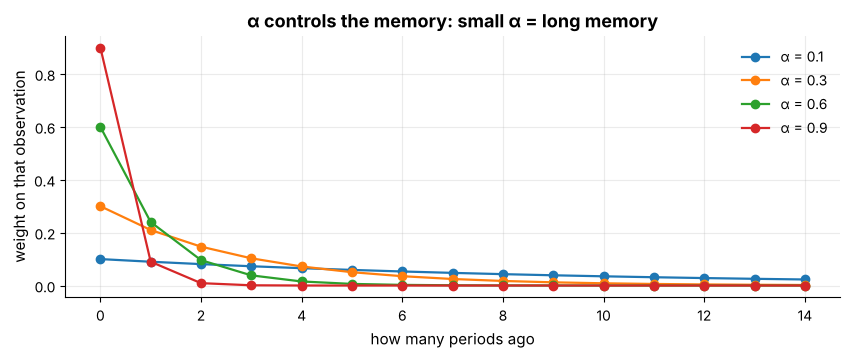

In [4]:
j = np.arange(0, 15)
fig, ax = plt.subplots(figsize=(10, 3.4))
for a in (0.1, 0.3, 0.6, 0.9):
    ax.plot(j, a * (1 - a) ** j, marker="o", label=f"α = {a}")
ax.set(xlabel="how many periods ago", ylabel="weight on that observation", title="α controls the memory: small α = long memory"); ax.legend(); plt.show()

| α near… | Behaviour | Good for |
|---|---|---|
| **0** | very long memory, ignores today's news | noisy, stable series |
| **1** | almost the naive forecast (just yesterday) | series that jump around: random-walk-like |

### SES by hand (so there's no magic)

In [5]:
def ses_levels(y, alpha):
    y = np.asarray(y, float)
    level = np.empty(len(y)); level[0] = y[0]                  # simplest start: first observation
    for t in range(1, len(y)):
        level[t] = alpha * y[t] + (1 - alpha) * level[t - 1]
    return level

lv = ses_levels(m, 0.5)
ref = SimpleExpSmoothing(m, initialization_method="known", initial_level=float(m.iloc[0])).fit(smoothing_level=0.5, optimized=False).level
print("matches statsmodels:", np.allclose(lv, ref))

matches statsmodels: True


In [6]:
fit_ses = SimpleExpSmoothing(m, initialization_method="estimated").fit()
print("statsmodels optimised alpha:", round(float(fit_ses.params["smoothing_level"]), 3))

statsmodels optimised alpha: 1.0


> 💡 **Professor's aside.** Statsmodels picks α by minimising the sum of squared **one-step-ahead** errors. A high optimised α (like here) is the data telling you: *"I behave like a random walk: trust the latest point."*

---
### 🧩 Exercise 1: Pick α yourself  ⭐⭐

Scan α over `np.linspace(0.05, 0.95, 19)`. For each α compute the SES levels with `ses_levels(m, alpha)`
and the **one-step-ahead SSE**: the forecast for month *t+1* is the level at *t*, so
`SSE = Σ (m[t+1] - level[t])²` for t = 0…n-2.
Store the SSEs in a list `sse_list` and the best α in `best_alpha`.

<details><summary>💡 Hint 1: gentle nudge</summary>

Write a loop `for a in alphas:` and call `lv = ses_levels(m, a)` inside.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

One-step forecasts are `lv[:-1]`; the targets they are compared with are `m.to_numpy()[1:]`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`sse_list.append(np.sum((m.to_numpy()[1:] - lv[:-1]) ** 2))`, then `best_alpha = alphas[int(np.argmin(sse_list))]`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
alphas = np.linspace(0.05, 0.95, 19)
sse_list = []
best_alpha = None

In [ ]:
try:
    ag.check("19 SSE values", len(sse_list) == 19)
    ag.check("best_alpha is the arg-min of your SSEs", best_alpha is not None and np.isclose(best_alpha, alphas[int(np.argmin(sse_list))]))
    opt = float(SimpleExpSmoothing(m, initialization_method="known", initial_level=float(m.iloc[0])).fit().params["smoothing_level"])
    ag.check(f"close to statsmodels' optimum ({opt:.2f})", best_alpha is not None and abs(best_alpha - opt) < 0.1)
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

---
## 3 · Holt's linear trend: adding a slope

SES forecasts are flat. If prices are climbing 7 % a year, flat is wrong in a predictable way. **Holt (1957)** keeps *two* running estimates:

$$\begin{aligned}
\ell_t &= \alpha\, y_t + (1-\alpha)(\ell_{t-1} + b_{t-1}) &&\text{(level)}\\
b_t &= \beta\,(\ell_t - \ell_{t-1}) + (1-\beta)\, b_{t-1} &&\text{(trend / slope)}\\
\hat y_{t+h\mid t} &= \ell_t + h\, b_t
\end{aligned}$$

Trouble: a straight line extended 24 months ahead can run away. The **damped** trend multiplies the slope by $\phi<1$ each step, so the line gradually flattens:
$\hat y_{t+h} = \ell_t + (\phi+\phi^2+\dots+\phi^h)\,b_t$.

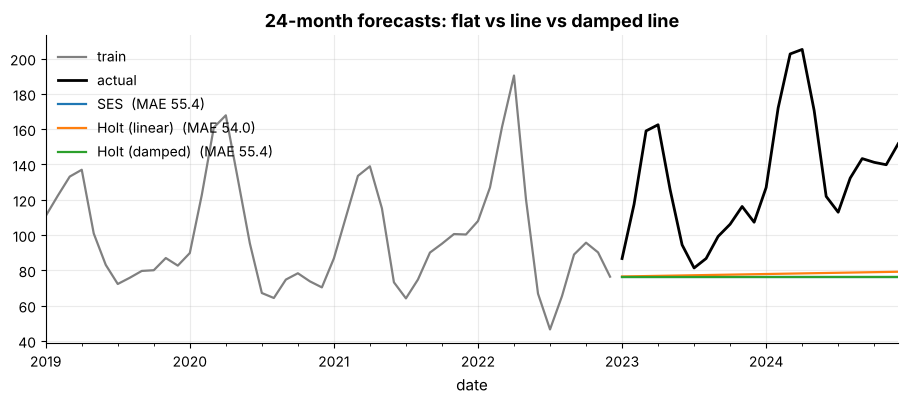

In [9]:
train, test = m.iloc[:-24], m.iloc[-24:]
fits = {
    "SES": ExponentialSmoothing(train, trend=None).fit(),
    "Holt (linear)": ExponentialSmoothing(train, trend="add").fit(),
    "Holt (damped)": ExponentialSmoothing(train, trend="add", damped_trend=True).fit(),
}
fig, ax = plt.subplots(figsize=(11, 4))
train.iloc[-48:].plot(ax=ax, color="gray", label="train"); test.plot(ax=ax, color="black", lw=2, label="actual")
for name, f in fits.items():
    f.forecast(24).plot(ax=ax, label=f"{name}  (MAE {ag.mae(test, f.forecast(24)):.1f})")
ax.legend(); ax.set_title("24-month forecasts: flat vs line vs damped line"); plt.show()

---
## 4 · Holt-Winters: adding seasonality

Add a third state: **seasonal indices** $s_t$ with period $m$ (12 for monthly data).

| Variant | Seasonal effect | Use when |
|---|---|---|
| **Additive** | $\hat y = \ell + b + s$ | seasonal swing is a constant *amount* |
| **Multiplicative** | $\hat y = (\ell + b)\times s$ | swing is a constant *percentage* (grows with level) |

Since our prices drift upward, we expect **multiplicative** to fit better. Let's let the data decide.

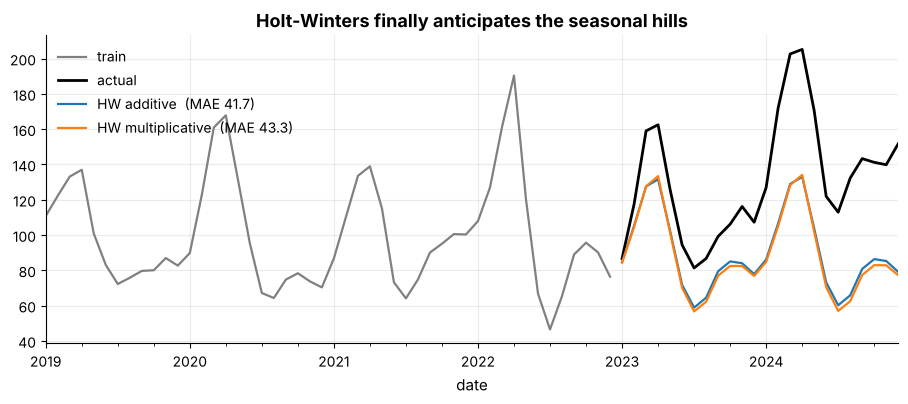

multiplicative seasonal index by calendar month:
 {1: 1.05, 2: 1.3, 3: 1.59, 4: 1.66, 5: 1.26, 6: 0.87, 7: 0.71, 8: 0.77, 9: 0.96, 10: 1.03, 11: 1.02, 12: 0.95}


In [10]:
hw = {
    "HW additive": ExponentialSmoothing(train, trend="add", damped_trend=True, seasonal="add", seasonal_periods=12).fit(),
    "HW multiplicative": ExponentialSmoothing(train, trend="add", damped_trend=True, seasonal="mul", seasonal_periods=12).fit(),
}
fig, ax = plt.subplots(figsize=(11, 4))
train.iloc[-48:].plot(ax=ax, color="gray", label="train"); test.plot(ax=ax, color="black", lw=2, label="actual")
for name, f in hw.items():
    f.forecast(24).plot(ax=ax, label=f"{name}  (MAE {ag.mae(test, f.forecast(24)):.1f})")
ax.legend(); ax.set_title("Holt-Winters finally anticipates the seasonal hills"); plt.show()

# peek inside: what did the model learn?
f = hw["HW multiplicative"]
last12 = f.season.iloc[-12:]                                   # the most recent seasonal indices the model holds
seasonal_idx = pd.Series(last12.to_numpy(), index=last12.index.month).sort_index().round(2)
print("multiplicative seasonal index by calendar month:\n", seasonal_idx.to_dict())

**Reading the indices**: a value of 1.15 means "prices in that part of the cycle run 15 % above the underlying level"; 0.85 means 15 % below.
You can hand these numbers to the cooperative as a *planting & storage calendar*.

---
## 5 · The fair fight: walk-forward comparison
One split proves little. Let's refit every model at every origin (monthly refit; first window = 60 months; horizons 1–6).

In [11]:
def ets(**kw):
    return lambda train, h: ExponentialSmoothing(train, **kw).fit().forecast(h).to_numpy()

def ma_forecast(k):
    return lambda train, h: np.repeat(train.iloc[-k:].mean(), h)

models = {
    "naive": ag.naive_forecast,
    "seasonal naive": lambda tr, h: ag.seasonal_naive_forecast(tr, h, m=12),
    "MA(3)": ma_forecast(3),
    "MA(12)": ma_forecast(12),
    "SES": ets(trend=None),
    "Holt": ets(trend="add"),
    "Holt damped": ets(trend="add", damped_trend=True),
    "HW additive": ets(trend="add", damped_trend=True, seasonal="add", seasonal_periods=12),
    "HW multiplicative": ets(trend="add", damped_trend=True, seasonal="mul", seasonal_periods=12),
}
results = {name: ag.walk_forward(m, f, initial=60, horizon=6, step=1) for name, f in models.items()}
board = ag.score_table(results, y_train=m.iloc[:60])
board

,MAE,RMSE,MAPE,MASE
HW multiplicative,13.677,17.131,13.660,1.155
HW additive,16.464,22.375,16.837,1.390
seasonal naive,20.769,25.038,18.249,1.754
MA(12),27.921,36.363,25.970,2.358
SES,39.805,49.046,39.489,3.361
naive,39.805,49.046,39.489,3.361
MA(3),40.865,49.145,39.860,3.451
Holt damped,57.893,75.403,60.853,4.889
Holt,77.628,107.849,83.105,6.556


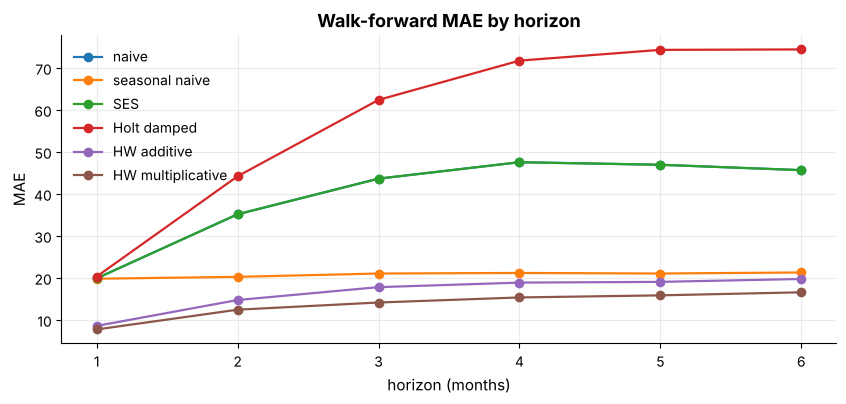

In [12]:
by_h = pd.DataFrame({n: r.groupby("h").apply(lambda d: ag.mae(d.actual, d.forecast)) for n, r in results.items()})
ax = by_h[["naive", "seasonal naive", "SES", "Holt damped", "HW additive", "HW multiplicative"]].plot(marker="o", figsize=(10, 4))
ax.set(xlabel="horizon (months)", ylabel="MAE", title="Walk-forward MAE by horizon"); plt.show()

What the scoreboard teaches (your numbers may differ in the decimals, not the story):
1. **Naive is hard to beat at h = 1**, as always.
2. Models with **seasonality** pull ahead as the horizon lengthens.
3. The **multiplicative** variant usually edges the additive one because the seasonal swing scales with price.
4. Complexity doesn't guarantee wins: *Holt without seasonality* can be worse than SES at long horizons because it extrapolates a trend that the seasonal swing contaminates.

## 6 · Choosing among smoothing models

```
Is there a trend?   no  ──►  Is there seasonality?  no  ──►  SES
                    │                               yes ──►  Holt-Winters (no trend term)
                    yes ──►  Is there seasonality?  no  ──►  Holt (damped for long horizons)
                                                    yes ──►  Holt-Winters (additive or multiplicative)
```

---
### 🧩 Exercise 2: Which moving-average window wins?  ⭐⭐

Using `ag.walk_forward` on the monthly series `m` (initial=60, horizon=1, step=1), evaluate the MA forecaster for window sizes
`k in [1, 2, 3, 6, 12]`. Store the h=1 **MAE** per window in dict `ma_mae` (`{k: mae}`) and the best window in `best_k`.
Which window is best, and is that a surprise given the earlier discussion?

<details><summary>💡 Hint 1: gentle nudge</summary>

A forecaster is any function `(train, h) -> array`. For MA(k): `lambda train, h: np.repeat(train.iloc[-k:].mean(), h)`: careful with Python closures in a loop!

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

Use a helper `def make_ma(k): return lambda train, h: ...` to capture `k` correctly.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`res = ag.walk_forward(m, make_ma(k), initial=60, horizon=1)`, then `ag.mae(res.actual, res.forecast)`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
ma_mae = {}
best_k = None

In [ ]:
try:
    ag.check("evaluated 5 windows", set(ma_mae) == {1, 2, 3, 6, 12})
    ag.check("best_k is arg-min", best_k == min(ma_mae, key=ma_mae.get))
    ag.check("k=1 is exactly the naive forecast", np.isclose(ma_mae[1], ag.mae(*[(lambda r: (r.actual, r.forecast))(ag.walk_forward(m, ag.naive_forecast, 60, 1))][0])))
    ag.check("the shortest window wins for a persistent series (h=1)", best_k in (1, 2), "persistence: recent data matters most one step ahead")
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

---
### 🧩 Exercise 3: Does damping help at long horizons?  ⭐⭐

Compare **Holt (linear)** and **Holt damped** at **12-month** horizons using walk-forward on `m`
(initial=60, horizon=12, step=3 to keep it quick). Store the MAE of each in `mae_linear` and `mae_damped`,
and set `damping_helps = mae_damped < mae_linear`.

<details><summary>💡 Hint 1: gentle nudge</summary>

Build the two forecasters with the `ets(...)` helper from section 5: `ets(trend='add')` and `ets(trend='add', damped_trend=True)`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`r = ag.walk_forward(m, forecaster, initial=60, horizon=12, step=3)`; `mae = ag.mae(r.actual, r.forecast)`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

Remember `damping_helps` should be a plain `bool`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
mae_linear = None
mae_damped = None
damping_helps = None

In [ ]:
try:
    ag.check("both MAEs are positive floats", all(isinstance(v, float) and v > 0 for v in (mae_linear, mae_damped)))
    ag.check("damping_helps is a bool consistent with your MAEs", damping_helps == (mae_damped < mae_linear))
    ag.check("damping does help at 12 months (a straight line overshoots)", damping_helps is True)
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

> ⚠️ **Common pitfall.** Don't pick a model by its **in-sample** fit (`fit.aic`, `fit.sse`) alone. A flexible model always fits the past better; only out-of-sample, walk-forward error tells you about the future.

        ---
        ## 🧾 Recap
        - **Moving average**: flat forecast, lag vs noise trade-off set by the window.
- **SES**: level only; α is the memory knob; weights decay as α(1-α)^j.
- **Holt**: level + trend (damp it for long horizons). **Holt-Winters**: + seasonal indices (additive or multiplicative).
- Smoothing models are cheap, transparent, and strong baselines, and the seasonal indices are a business insight in themselves.
- Select models with **walk-forward error by horizon**, not in-sample fit.

**Next up:** Lesson 7.5; ARIMA, SARIMA and SARIMAX: modelling autocorrelation directly.